In [219]:
using Pkg
Pkg.status()
using Interact
using Random, LinearAlgebra,GLM, DataFrames  # Random for rand(), LinearAlgebra for I (identity)

Status `C:\Users\FERNANDO\.julia\environments\v1.11\Project.toml`
  [336ed68f] CSV v0.10.15
  [324d7699] CategoricalArrays v1.0.1
  [a93c6f00] DataFrames v1.7.1
  [38e38edf] GLM v1.9.0
  [7073ff75] IJulia v1.30.3
  [c601a237] Interact v0.10.5
  [91a5bcdd] Plots v1.40.19
  [2913bbd2] StatsBase v0.34.6
  [3eaba693] StatsModels v0.7.6
  [0f1e0344] WebIO v0.8.21


In [220]:
print("Ingrese el número de observaciones: ")
n= parse(Int, readline())
print("Ingrese el número de varaibles de x_1: ")
k_1= parse(Int, readline())
print("Ingrese el número de varaibles de x_2: ")
k_2= parse(Int, readline())

println("Resultados:")
println("n = $n, k1 = $k_1, k2 = $k_2")

Ingrese el número de observaciones: Ingrese el número de varaibles de x_1: Ingrese el número de varaibles de x_2: Resultados:
n = 100, k1 = 3, k2 = 4


In [221]:
# Vector y (n × 1)
y = rand(n) # solo necesito usar rand y determinar las filas y columnas

# Matrix x_1 (n × k1)
x_1 = rand(n, k_1) # necesito especificar primero filas y luego columnas

# Matrix x_2 (n × k2)
x_2 = rand(n, k_2)

# Identity matrix (n × n)
iden = Matrix(I, n, n)


100×100 Matrix{Bool}:
 1  0  0  0  0  0  0  0  0  0  0  0  0  …  0  0  0  0  0  0  0  0  0  0  0  0
 0  1  0  0  0  0  0  0  0  0  0  0  0     0  0  0  0  0  0  0  0  0  0  0  0
 0  0  1  0  0  0  0  0  0  0  0  0  0     0  0  0  0  0  0  0  0  0  0  0  0
 0  0  0  1  0  0  0  0  0  0  0  0  0     0  0  0  0  0  0  0  0  0  0  0  0
 0  0  0  0  1  0  0  0  0  0  0  0  0     0  0  0  0  0  0  0  0  0  0  0  0
 0  0  0  0  0  1  0  0  0  0  0  0  0  …  0  0  0  0  0  0  0  0  0  0  0  0
 0  0  0  0  0  0  1  0  0  0  0  0  0     0  0  0  0  0  0  0  0  0  0  0  0
 0  0  0  0  0  0  0  1  0  0  0  0  0     0  0  0  0  0  0  0  0  0  0  0  0
 0  0  0  0  0  0  0  0  1  0  0  0  0     0  0  0  0  0  0  0  0  0  0  0  0
 0  0  0  0  0  0  0  0  0  1  0  0  0     0  0  0  0  0  0  0  0  0  0  0  0
 0  0  0  0  0  0  0  0  0  0  1  0  0  …  0  0  0  0  0  0  0  0  0  0  0  0
 0  0  0  0  0  0  0  0  0  0  0  1  0     0  0  0  0  0  0  0  0  0  0  0  0
 0  0  0  0  0  0  0  0  0  0  0  0  1    

In [222]:
# los errores ya se definene como resultado de lo que viene a ser la regresión
# entonces nos dice que los residuos de la regresión de y sobre x_2
# estos residuos son equivalentes a: I-X_2 (X_2′X_2)^−1 X2′

# first step

M_2= iden - x_2*(inv(Transpose(x_2)*x_2) * Transpose(x_2))

# second setp 

x_1_tilde = M_2 * x_1
y_tilde = M_2 * y

#thrid 

b_1_tilde= inv(Transpose(x_1_tilde)*x_1_tilde) * (Transpose(x_1_tilde) * y_tilde) 

# ahora comparo mi resultado con el obtenido por una biblioteca

println("parametros = $b_1_tilde")


parametros = [0.18008513819246624, 0.25660527589421, 0.08761383006683683]


In [223]:
# Combinar x_1 y x_2
X = hcat(x_1, x_2)

# le damos nombre a las columnas
nombres = Symbol.("x" .* string.(1:(k_1+k_2)))
# contruimos la data
df = DataFrame(X, nombres)
df.y = y   # agregams la dependiente

100-element Vector{Float64}:
 0.35861783227415656
 0.3868697904042231
 0.7827889235684694
 0.35627238593030763
 0.8559057797927683
 0.4899770403820185
 0.7531441181831533
 0.05074664535734352
 0.3782998011829172
 0.37042597230638363
 0.9649162829193789
 0.49007826936148713
 0.9913868586709927
 ⋮
 0.6590517156157072
 0.28931213387057975
 0.557840749979025
 0.5672594807159854
 0.6480266038402152
 0.35445220833739255
 0.7102420622314245
 0.5001716843269909
 0.8589374639169481
 0.9155676326588003
 0.5675014239445273
 0.38424713072334393

In [224]:
print(df)

100×8 DataFrame
 Row │ x1          x2         x3         x4          x5          x6           x7          y           
     │ Float64     Float64    Float64    Float64     Float64     Float64      Float64     Float64     
─────┼────────────────────────────────────────────────────────────────────────────────────────────────
   1 │ 0.569995    0.0458864  0.404033   0.735009    0.463784    0.818731     0.506952    0.358618
   2 │ 0.551691    0.0297314  0.188107   0.230731    0.349938    0.988662     0.664855    0.38687
   3 │ 0.541792    0.357067   0.211147   0.715971    0.467149    0.587092     0.953354    0.782789
   4 │ 0.695774    0.239579   0.441867   0.934025    0.575709    0.26513      0.968771    0.356272
   5 │ 0.0989972   0.883866   0.812596   0.798633    0.554966    0.8905       0.916365    0.855906
   6 │ 0.745816    0.695683   0.26282    0.701219    0.195184    0.838795     0.701775    0.489977
   7 │ 0.879989    0.935318   0.701267   0.366801    0.685258    0.442821     0.98

In [225]:
ols_model = lm(X, y)   
coeficientes = coef(ols_model)
coef_x_1=coeficientes[1:k_1]
println("parametros estimados con librerias = $coef_x_1")
println("parametros calculados con matriz de residuos= $b_1_tilde")


parametros estimados con librerias = [0.18008513819246671, 0.2566052758942107, 0.08761383006683668]
parametros calculados con matriz de residuos= [0.18008513819246624, 0.25660527589421, 0.08761383006683683]


# PART 2

Resultados R² por grado de polinomio:
10×3 DataFrame
 Row │ Degree  R2_train  R2_test    
     │ Int64   Float64   Float64    
─────┼──────────────────────────────
   1 │      1  0.590572   0.225194
   2 │      2  0.722285   0.537105
   3 │      3  0.722387   0.533283
   4 │      4  0.722388   0.533497
   5 │      5  0.722567   0.532422
   6 │      6  0.734341   0.518117
   7 │      7  0.726751   0.52875
   8 │      8  0.637382   0.264971
   9 │      9  0.553709   0.0658491
  10 │     10  0.46773   -0.114663


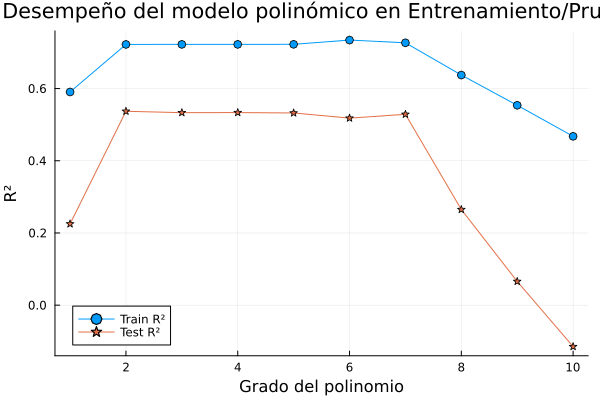

In [226]:
# ------------------------------------------------------------
# 1. Generar datos base (simulación con ruido)
# ------------------------------------------------------------
using Random
using DataFrames
using GLM

Random.seed!(42)

n = 100
x = LinRange(0, 10, n)
y = 3 .+ 2 .* x .+ 0.5 .* x.^2 .- 0.05 .* x.^3 .+ randn(n) .* 5

# ------------------------------------------------------------
# 2. Dividir en conjuntos de entrenamiento y prueba
# ------------------------------------------------------------
# Aquí se usa un índice aleatorio para crear la división
indices = randperm(n)  # genera una permutación aleatoria de los índices
train_size = floor(Int, 0.7 * n)  # tamaño del conjunto de entrenamiento

X_train = x[indices[1:train_size]]
X_test = x[indices[train_size+1:end]]
y_train = y[indices[1:train_size]]
y_test = y[indices[train_size+1:end]]

# ------------------------------------------------------------
# 3. Función para calcular R²
# ------------------------------------------------------------
function r2score(y_true, y_pred)
    ss_tot = sum((y_true .- mean(y_true)).^2)
    ss_res = sum((y_true .- y_pred).^2)
    return 1 - (ss_res / ss_tot)
end

# ------------------------------------------------------------
# 4. Evaluación del modelo polinómico con bucle
# ------------------------------------------------------------
results = []

# Probar polinomios desde el grado 1 hasta el 10
for degree in 1:10
    # Crear transformador polinómico (equivalente a PolynomialFeatures)
    X_train_poly = hcat([X_train.^i for i in 1:degree]...)
    X_test_poly = hcat([X_test.^i for i in 1:degree]...)
    
    # Ajustar el modelo de regresión lineal
    model = lm(X_train_poly, y_train)
    
    # Predicciones
    y_train_pred = predict(model, X_train_poly)
    y_test_pred = predict(model, X_test_poly)
    
    # Calcular R² en entrenamiento y prueba
    r2_train = r2score(y_train, y_train_pred)
    r2_test = r2score(y_test, y_test_pred)
    
    # Guardar resultados
    push!(results, (Degree=degree, R2_train=r2_train, R2_test=r2_test))
end

# Convertir resultados a DataFrame
df_results = DataFrame(results)

# ------------------------------------------------------------
# 5. Mostrar resultados
# ------------------------------------------------------------
println("Resultados R² por grado de polinomio:")
println(df_results)

# ------------------------------------------------------------
# 6. Graficar desempeño
# ------------------------------------------------------------
using Plots
plot(df_results.Degree, df_results.R2_train, marker=:o, label="Train R²", xlabel="Grado del polinomio", ylabel="R²", title="Desempeño del modelo polinómico en Entrenamiento/Prueba")
plot!(df_results.Degree, df_results.R2_test, marker=:s, label="Test R²", grid=true)


# PART 3
---
# 3a Cleaning (2 points)

In this section you'll need to do the following:

- Create a variable area2 that's the square of area (0.25 points)
- Convert 'hasparkingspace', 'hasbalcony', 'haselevator', 'hassecurity', 'hasstorageroom' to dummy variables (where 'yes' 'no' get mapped to 1, 0) (0.75 points)
- For each last digit of area (i.e. 0,1,...,9), create a dummy variable if the last digit of area happens to be that number. Name your variables accordingly (e.g. end_0, end_1, ...end_9). (1 point)

In [227]:
# ------------------------------------------------------------
# 1. Cargar el CSV y ver las primeras filas
# ------------------------------------------------------------
using DataFrames
using CSV

# Leer el archivo CSV
#df = CSV.File("/Users/rominarattoyanez/Downloads/apartments.csv") |> DataFrame
df = CSV.File("C:/Users/FERNANDO/Documents/GitHub/High_Dimensional_Linear_Models/Python/input/apartments.csv") |> DataFrame
# Mostrar primeras filas
println(first(df, 5))


5×21 DataFrame
 Row │ id                                price    month  area   type               rooms  centredistance  schooldistance  clinicdistance  postofficedistance  kindergartendistance  restaurantdistance  collegedistance  pharmacydistance  ownership    buildingmaterial  hasparkingspace  hasbalcony  haselevator  hassecurity  hasstorageroom 
     │ String                            Int64    Int64  Int64  String31?          Int64  Float64         Float64?        Float64?        Float64?            Float64?              Float64?            Float64?         Float64?          String15     String15?         String3          String3     String3?     String3      String3        
─────┼─────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────

In [228]:
# ------------------------------------------------------------
# 2. Crear nueva variable 'area2'
# ------------------------------------------------------------
df[!, "area2"] = df[!, "area"].^2

# Mostrar las columnas
println(names(df))

["id", "price", "month", "area", "type", "rooms", "centredistance", "schooldistance", "clinicdistance", "postofficedistance", "kindergartendistance", "restaurantdistance", "collegedistance", "pharmacydistance", "ownership", "buildingmaterial", "hasparkingspace", "hasbalcony", "haselevator", "hassecurity", "hasstorageroom", "area2"]


In [229]:
# ------------------------------------------------------------
# 3. Convertir las variables binarias en 0 y 1
# ------------------------------------------------------------
cols = ["hasparkingspace", "hasbalcony", "haselevator", "hassecurity", "hasstorageroom"]

for c in cols
    # Reemplazamos los valores Missing por "no"
    df[!, c] .= coalesce.(string.(df[!, c]), "no")

    # Convertir las respuestas "yes"/"no" a 1/0
    df[!, c] .= string.(df[!, c]) .== "yes"
end

In [230]:
# ------------------------------------------------------------
# 4. Obtener el último dígito de 'area'
# ------------------------------------------------------------
df[!, "area_last_digit"] = df[!, "area"] .% 10

# Crear las variables dummies para el último dígito de 'area'
for d in 0:9
    df[!, "end_$d"] = df[!, "area_last_digit"] .== d
end

# Eliminar la columna auxiliar
select!(df, Not(:area_last_digit))


Row,id,price,month,area,type,rooms,centredistance,schooldistance,clinicdistance,postofficedistance,kindergartendistance,restaurantdistance,collegedistance,pharmacydistance,ownership,buildingmaterial,hasparkingspace,hasbalcony,haselevator,hassecurity,hasstorageroom,area2,end_0,end_1,end_2,end_3,end_4,end_5,end_6,end_7,end_8,end_9
,String,Int64,Int64,Int64,String31?,Int64,Float64,Float64?,Float64?,Float64?,Float64?,Float64?,Float64?,Float64?,String15,String15?,Bool,Bool,Bool,Bool,Bool,Int64,Bool,Bool,Bool,Bool,Bool,Bool,Bool,Bool,Bool,Bool
1,a01d82c9529f98a54d64b9e061c9a73b,1199999,1,105,apartmentBuilding,4,5.06,1.08,0.949,0.623,0.791,1.054,3.062,0.335,condominium,brick,false,true,true,false,false,11025,false,false,false,false,false,true,false,false,false,false
2,8373aa373dbc3fe7ca3b7434166b8766,650000,1,73,tenement,3,3.24,0.275,0.672,0.367,0.246,0.3,1.857,0.28,condominium,brick,false,false,false,false,false,5329,false,false,false,true,false,false,false,false,false,false
3,7d0c31d5409caab173571cce3dcdf702,590000,1,69,blockOfFlats,3,3.94,0.139,1.336,0.926,0.93,0.071,0.786,0.304,condominium,brick,false,true,false,false,true,4761,false,false,false,false,false,false,false,false,false,true
4,3eaa36a59b9354206703b5f6b2f2ff1d,584999,1,42,blockOfFlats,2,5.19,0.209,1.533,0.201,0.319,0.157,2.722,0.257,condominium,missing,false,true,false,false,false,1764,false,false,true,false,false,false,false,false,false,false
5,027b30cebbc49faf3094421b741ddd56,363000,1,46,blockOfFlats,2,1.65,0.25,0.624,0.51,0.177,0.232,0.986,0.273,condominium,concreteSlab,false,false,false,false,true,2116,false,false,false,false,false,false,true,false,false,false
6,27437e173a8c37d5002c0bf69c848b7c,717000,1,81,tenement,3,1.76,0.083,0.257,0.294,0.151,0.102,0.256,0.301,condominium,brick,false,false,false,false,true,6561,false,true,false,false,false,false,false,false,false,false
7,39404087c054348c27522c74ca21a973,689000,1,70,blockOfFlats,3,3.35,0.269,1.364,0.247,0.122,0.388,1.589,0.194,cooperative,concreteSlab,false,true,true,false,true,4900,true,false,false,false,false,false,false,false,false,false
8,7a3b00507c086fcf83562f22bb5d01fc,790000,1,67,apartmentBuilding,3,1.61,0.501,0.973,0.713,0.067,0.052,0.988,0.215,condominium,brick,true,true,true,false,false,4489,false,false,false,false,false,false,false,true,false,false
9,24af7cc54099d7930535543827604a9d,560000,1,69,blockOfFlats,3,2.29,0.371,0.592,0.213,0.222,0.24,0.583,0.721,condominium,brick,false,true,false,false,true,4761,false,false,false,false,false,false,false,false,false,true


In [231]:
# ------------------------------------------------------------
# 5. Definir variables
# ------------------------------------------------------------
last_digit_dummies = [Symbol("end_$i") for i in 0:8]  # Excluir 'end_9' como base

# Variables continuas
continuous_vars = ["area", "area2", "schooldistance", "clinicdistance", "postofficedistance",
                   "kindergartendistance", "restaurantdistance", "collegedistance", "pharmacydistance"]

# Variables binarias
binary_vars = ["hasparkingspace", "hasbalcony", "haselevator", "hassecurity", "hasstorageroom"]

# Variables categóricas
categorical_vars = ["month", "type", "rooms", "ownership", "buildingmaterial"]

println("Last digit dummies:")
println(last_digit_dummies)

println("\nContinuous variables:")
println(continuous_vars)

println("\nBinary variables:")
println(binary_vars)

println("\nCategorical variables:")
println(categorical_vars)


Last digit dummies:


[:end_0, :end_1, :end_2, :end_3, :end_4, :end_5, :end_6, :end_7, :end_8]

Continuous variables:
["area", "area2", "schooldistance", "clinicdistance", "postofficedistance", "kindergartendistance", "restaurantdistance", "collegedistance", "pharmacydistance"]

Binary variables:
["hasparkingspace", "hasbalcony", "haselevator", "hassecurity", "hasstorageroom"]

Categorical variables:
["month", "type", "rooms", "ownership", "buildingmaterial"]


In [232]:
println(names(df)) 

["id", "price", "month", "area", "type", "rooms", "centredistance", "schooldistance", "clinicdistance", "postofficedistance", "kindergartendistance", "restaurantdistance", "collegedistance", "pharmacydistance", "ownership", "buildingmaterial", "hasparkingspace", "hasbalcony", "haselevator", "hassecurity", "hasstorageroom", "area2", "end_0", "end_1", "end_2", "end_3", "end_4", "end_5", "end_6", "end_7", "end_8", "end_9"]


# 3b Linear model estimation (4 points)

---
1 Regress 'price' against the following covariates:

- Area's last digit dummies (ommit 9 to have a base category)
- Area, area squared
- Distance from apartment to point of interest (such as school, clinic, postoffice, etc.)
'hasparkingspace', 'hasbalcony', 'haselevator', 'hassecurity', 'hasstorageroom'
- Month, type, rooms, ownership, buildingmaterial (treat these as categorical variables)

Print a summary table and comment your results on the area's last digit dummy when the area's last digit is 0 (end_0).

(2 points)

In [243]:
# ------------------------------------------------------------
# 6. Ajustar el modelo de regresión lineal (modelo completo)
# ------------------------------------------------------------
# Asegúrate de tener StatsModels y GLM instalados
using DataFrames
using GLM
using StatsModels
using LinearAlgebra
using CategoricalArrays

# ------------------------------------------------------------
# 6. Ajustar el modelo de regresión lineal (modelo completo)
# ------------------------------------------------------------
# Definir la fórmula correctamente con `C()` para las variables categóricas
# Convertir las variables categóricas manualmente a tipo Categorical
df.month = categorical(df.month)
df.type = categorical(df.type)
df.rooms = categorical(df.rooms)
df.ownership = categorical(df.ownership)
df.buildingmaterial = categorical(df.buildingmaterial)
df_clean = dropmissing(df)
formula_1 = @formula(price ~ area + area2 +
                   schooldistance + clinicdistance + postofficedistance +
                   kindergartendistance + restaurantdistance +
                   collegedistance + pharmacydistance +
                   hasparkingspace + hasbalcony + haselevator + hassecurity + hasstorageroom +
                   month + type + rooms + ownership + buildingmaterial +
                   end_0 + end_1 + end_2 + end_3 + end_4 + end_5 + end_6 + end_7 + end_8)

# 1) Construir Y y X EXACTAMENTE como lo usa la fórmula (mismas dummies, misma base, mismas filas)
y_mat, X_mat = modelmatrix(formula_1, df_clean)

# 2) OLS completo (referencia)
full = lm(formula_1, df_clean)  # Ajustar el modelo OLS
beta_full = coef(full)[31]  # Acceder al coeficiente de 'end_0'
println("Coef (full OLS) end_0: ", beta_full)


Coef (full OLS) end_0: 25894.666481057044


In [242]:
full


StatsModels.TableRegressionModel{LinearModel{GLM.LmResp{Vector{Float64}}, GLM.DensePredChol{Float64, CholeskyPivoted{Float64, Matrix{Float64}, Vector{Int64}}}}, Matrix{Float64}}

price ~ 1 + area + area2 + schooldistance + clinicdistance + postofficedistance + kindergartendistance + restaurantdistance + collegedistance + pharmacydistance + hasparkingspace + hasbalcony + haselevator + hassecurity + hasstorageroom + month + type + rooms + ownership + buildingmaterial + end_0 + end_1 + end_2 + end_3 + end_4 + end_5 + end_6 + end_7 + end_8

Coefficients:
───────────────────────────────────────────────────────────────────────────────────────────────────────────────
                                         Coef.     Std. Error       t  Pr(>|t|)       Lower 95%       Upper 95%
───────────────────────────────────────────────────────────────────────────────────────────────────────────────
(Intercept)                          1.21286e5  12848.2          9.44    <1e-20   96103.5             1.464

- El coeficiente de end_0 se interpreta en relación con la categoría base, que es end_9 (departamentos cuyo área termina en 9).
- Signo positivo: los departamentos cuyo área termina en 0 tienen un precio mayor que los que terminan en 9, manteniendo constantes las demás variables del modelo (área, área², distancias, características, tipo de construcción, etc.).
- Magnitud: el precio promedio es ≈ 25894 (soles) más alto.
- Significancia estadística: el p-valor = 0.000 indica que este efecto es robusto y difícilmente atribuible al azar.

In [235]:
# recordar que se crea n-1 dummys por eso se estan generando la cantidad de categorias que posee cadavariable
println("Categorías de 'month': ", length(levels(df.month)))
println("Categorías de 'type': ", length(levels(df.type)))
println("Categorías de 'rooms': ", length(levels(df.rooms)))
println("Categorías de 'ownership': ", length(levels(df.ownership)))
println("Categorías de 'buildingmaterial': ", length(levels(df.buildingmaterial)))

Categorías de 'month': 6
Categorías de 'type': 3
Categorías de 'rooms': 6
Categorías de 'ownership': 3
Categorías de 'buildingmaterial': 2


In [ ]:
# ------------------------------------------------------------
# 7. Regressión de residuos (partialling-out)
# ------------------------------------------------------------
using StatsModels

using GLM
# 1) Construir Y y X EXACTAMENTE como lo usa la fórmula (mismas dummies, misma base, mismas filas)
X_mat = modelmatrix(formula_1, df_clean)
y_mat = df_clean.price 

# omitir la columna end_0 la de la posición 31

n_rows = size(X_mat, 1)
intercept_column = ones(n_rows)  # Columna de unos
X_mat_po_0 = X_mat[:, Not(30)] # po: partialling out, es gracioso porque en los coeficientes deberia de ser la posición número 31 pero cuando extraigo la matriz de valores del modelo, esta sale sin el intercepto
X_mat_po=hcat(intercept_column, X_mat_po_0)
W = X_mat_po  # NO TIENE INTERCEPTO
x = X_mat[:,30]
y = y_mat              # columna 'price' como Serie

# Residualiza con los mismos controles W
model_y = lm(W, y)     

res_y = vec(residuals(model_y))          # Obtiene los residuos de y

model_x = lm(W, x)     

res_x = vec(residuals(model_x))          # Obtiene los residuos de y

# lo convertiremos en matriz para forzar
df_residual = DataFrame(res_x=res_x, res_y=res_y)

# Ajustar el modelo de regresión de residuos sin constante (solo para variables residualizadas)

partial_model = lm(@formula(res_y ~ 0+res_x ), df_residual) # esta es la forma correcta, aunque muchos se quejan sobre que deberian de parcharlo 

# Extraer el coeficiente de la regresión de los residuos
beta_partial = coef(partial_model)  # El coeficiente de la variable res_x

println("Coef (partialling-out) end_0: ", beta_partial)
println("Coef (full OLS) end_0: ", beta_full)



Coef (partialling-out) end_0: [25894.666481056312]
Coef (full OLS) end_0: 25894.666481057044


In [250]:

# 4) Verificación
# Compara los coeficientes obtenidos en la regresión completa y la de partialling-out
println("¿Iguales?: ", isapprox(beta_full, beta_partial[1], rtol=1e-10, atol=1e-8))



¿Iguales?: true


# 3c Price premium for area that ends in 0-digit (3 points)
---
1 Train the model
Estimate the same linear regression model, but only using apartments whose area does not end in 0.
(1.25 points)



In [257]:
# ------------------------------------------------------------
# 8. Ajustar el modelo solo con los datos donde 'end_0' es 0
# ------------------------------------------------------------
df_no_end0 = filter(row -> row.end_0 == 0, df_clean)

# Ajuste del modelo con df_no_end0
model_no_end0 = lm(formula_1, df_no_end0)


StatsModels.TableRegressionModel{LinearModel{GLM.LmResp{Vector{Float64}}, GLM.DensePredChol{Float64, CholeskyPivoted{Float64, Matrix{Float64}, Vector{Int64}}}}, Matrix{Float64}}

price ~ 1 + area + area2 + schooldistance + clinicdistance + postofficedistance + kindergartendistance + restaurantdistance + collegedistance + pharmacydistance + hasparkingspace + hasbalcony + haselevator + hassecurity + hasstorageroom + month + type + rooms + ownership + buildingmaterial + end_0 + end_1 + end_2 + end_3 + end_4 + end_5 + end_6 + end_7 + end_8

Coefficients:
────────────────────────────────────────────────────────────────────────────────────────────────────────────────
                                         Coef.     Std. Error       t  Pr(>|t|)        Lower 95%       Upper 95%
────────────────────────────────────────────────────────────────────────────────────────────────────────────────
(Intercept)                          1.2576e5   13527.7          9.30    <1e-19    99245.4             1

2 Predict prices
Using the estimated coefficients from step 1, predict apartment prices for the entire sample, including those apartments whose area ends in 0.
(1.25 points)

In [ ]:
# ------------------------------------------------------------
# 9. Predecir los precios para la muestra completa con el modelo ajustado en df_no_end0
# ------------------------------------------------------------
# vamos a hacerlo de forma más rudimentaria
# chaparemos la matriz total del modelo df_clean
# ahora con los coeficientes estimado la multiplicamos
# de esta forma la y de dimensiones n*1 donde n es el núemro de personas
# será igual al producto punto entre los coeficeintes y la matriz de X de dimensiones n*k, siendo n el número de personas
#  y(nx1)=X(nxk) . beta (kx1) 

X_mat_pred=hcat(intercept_column, X_mat)
betas=coef(model_no_end0)

pred_y= X_mat_pred * betas



59317-element Vector{Float64}:
      1.4818653666754065e6
 906173.4475443519
 781698.6225933767
 394568.3198794118
      1.0355727406561391e6
 821735.2240238264
      1.1744286268736757e6
 837855.0642163445
 624873.9133852544
 515208.31810708356
 999566.9262751528
      1.1184324876784286e6
 713487.3229250049
      ⋮
 381075.1075925221
 596315.1798899465
 982443.7830015948
      1.1201614502803476e6
 665131.4556617065
      1.7770111274048584e6
      1.211919276620178e6
      1.320315990319621e6
      1.4087980286609568e6
      1.3529279746024725e6
      1.4307823318114467e6
 815054.7667421808

3 Compare averages
For apartments whose area ends in 0, compute both the average actual price and the average predicted price.
Based on this comparison, try to determine whether apartments with areas ending in 0 are sold at a higher price than what the model predicts. (You don't need to make a statistical tests, just say a guess based on your results)
(0.5 points)

In [272]:
# ------------------------------------------------------------
# 10. Calcular promedios para los apartamentos cuyo área termina en 0
# ------------------------------------------------------------
df_end0 = filter(row -> row.end_0 == 1, df)

avg_actual = mean(df_end0.price)
avg_predicted = mean(pred_y)

println("Precio promedio real (end_0 = 1): $avg_actual")
println("Precio promedio predicho (end_0 = 1): $avg_predicted")

# Diferencia
println("Diferencia (real - predicho): ", avg_actual - avg_predicted)

Precio promedio real (end_0 = 1): 873616.2969725713
Precio promedio predicho (end_0 = 1): 844389.1910838613
Diferencia (real - predicho): 29227.105888710008
